In [1]:
import sys, torch
from packaging.version import Version

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torch CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if sys.version_info < (3, 12):
    raise RuntimeError("SAM 3.1 official setup requires Python 3.12 or newer. Select a current Colab runtime.")
if Version(torch.__version__.split('+')[0]) < Version("2.7.0"):
    raise RuntimeError("PyTorch 2.7+ is required. Select a current Colab runtime with a supported PyTorch build.")
if not torch.cuda.is_available():
    raise RuntimeError("GPU is not enabled. Select Runtime → Change runtime type → T4 GPU (or another CUDA GPU).")
if torch.version.cuda and Version(torch.version.cuda) < Version("12.6"):
    raise RuntimeError("The installed PyTorch CUDA runtime is older than 12.6. Use a current Colab GPU runtime.")

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Torch CUDA runtime: 13.0
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56


In [2]:
# Install the official SAM 3 repository and notebook dependencies.
from pathlib import Path
%cd /content
if not Path('/content/sam3').exists():
    !git clone https://github.com/facebookresearch/sam3.git
%cd /content/sam3
!pip -q install -e .
!pip -q install matplotlib pandas tqdm pillow scipy psutil yt-dlp


/content
Cloning into 'sam3'...
remote: Enumerating objects: 1525, done.
remote: Counting objects: 100% (68/68), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 1525 (delta 42), reused 29 (delta 29), pack-reused 1457 (from 3)
Receiving objects: 100% (1525/1525), 60.72 MiB | 38.57 MiB/s, done.
Resolving deltas: 100% (597/597), done.
/content/sam3
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for sam3 (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently tak

In [3]:
# Mount Google Drive and create persistent output folders.
from google.colab import drive, files
from pathlib import Path
import shutil, os, zipfile

drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/egg_cv_assignment')
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
VIDEO_DIR = PROJECT_DIR / 'video_tracking'
VIDEO_DIR.mkdir(parents=True, exist_ok=True)

print('Project folder:', PROJECT_DIR)
print('Video output folder:', VIDEO_DIR)


Mounted at /content/drive
Project folder: /content/drive/MyDrive/egg_cv_assignment
Video output folder: /content/drive/MyDrive/egg_cv_assignment/video_tracking


In [4]:
from huggingface_hub import login
login()


In [5]:
# Download and initialize the SAM 3.1 image segmentation model.
import torch
from sam3.model_builder import build_sam3_image_model, download_ckpt_from_hf
from sam3.model.sam3_image_processor import Sam3Processor

checkpoint_path = download_ckpt_from_hf(version='sam3.1')
print('Checkpoint downloaded to:', checkpoint_path)

DEVICE = 'cuda'
model = build_sam3_image_model(
    checkpoint_path=checkpoint_path,
    load_from_HF=False,
    device=DEVICE,
    eval_mode=True,
    enable_segmentation=True,
)

CONFIDENCE_THRESHOLD = 0.50
PROMPT = 'egg'
processor = Sam3Processor(
    model,
    device=DEVICE,
    confidence_threshold=CONFIDENCE_THRESHOLD,
)

AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print('SAM 3.1 image model loaded successfully.')
print('Autocast dtype:', AMP_DTYPE)


/content/sam3/sam3/model_builder.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/content/sam3/sam3/model/model_misc.py:71: UserWarning: Flash Attention is disabled as it requires a GPU with Ampere (8.0) CUDA capability.
  OLD_GPU, USE_FLASH_ATTN, MATH_KERNEL_ON = get_sdpa_settings()
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


config.json:   0%|          | 0.00/25.8k [00:00<?, ?B/s]

sam3.1_multiplex.pt: reconstructing file:   0%|          |  0.00B / 3.50GB            

sam3.1_multiplex.pt: downloading bytes:           |  0.00B            

Checkpoint downloaded to: /root/.cache/huggingface/hub/models--facebook--sam3.1/snapshots/daa63191845a41281374e725f4c9e51c7a824460/sam3.1_multiplex.pt
loaded /root/.cache/huggingface/hub/models--facebook--sam3.1/snapshots/daa63191845a41281374e725f4c9e51c7a824460/sam3.1_multiplex.pt and found missing and/or unexpected keys:
missing_keys=['backbone.vision_backbone.convs.3.conv_1x1.weight', 'backbone.vision_backbone.convs.3.conv_1x1.bias', 'backbone.vision_backbone.convs.3.conv_3x3.weight', 'backbone.vision_backbone.convs.3.conv_3x3.bias']
SAM 3.1 image model loaded successfully.
Autocast dtype: torch.bfloat16


In [6]:
# Frame-level segmentation helper used by the tracker.
import numpy as np
from PIL import Image


def segment_image(image: Image.Image):
    """Return per-instance binary masks, xyxy boxes, and confidence scores."""
    image = image.convert('RGB')
    state = processor.set_image(image)
    result = processor.set_text_prompt(state=state, prompt=PROMPT)

    masks_t = result['masks'].detach().cpu()
    # Official processor returns masks as [N, 1, H, W]. Convert to [N, H, W].
    if masks_t.ndim == 4 and masks_t.shape[1] == 1:
        masks_t = masks_t[:, 0]
    masks = masks_t.float().numpy().astype(bool)

    boxes = result['boxes'].detach().cpu().float().numpy()
    scores = result['scores'].detach().cpu().float().numpy()
    return masks, boxes, scores

print('Segmentation helper ready. Text prompt:', PROMPT)


Segmentation helper ready. Text prompt: egg


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
yt-dlp download failed: SameFileError("PosixPath('/content/egg_spinning_assignment.mp4') and PosixPath('/content/egg_spinning_assignment.mp4') are the same file")
Video file: /content/egg_spinning_assignment.mp4
Size (MB): 5.37
Resolution: 1280x720
FPS: 24.00 | Frames: 1440 | Duration: 60.0s


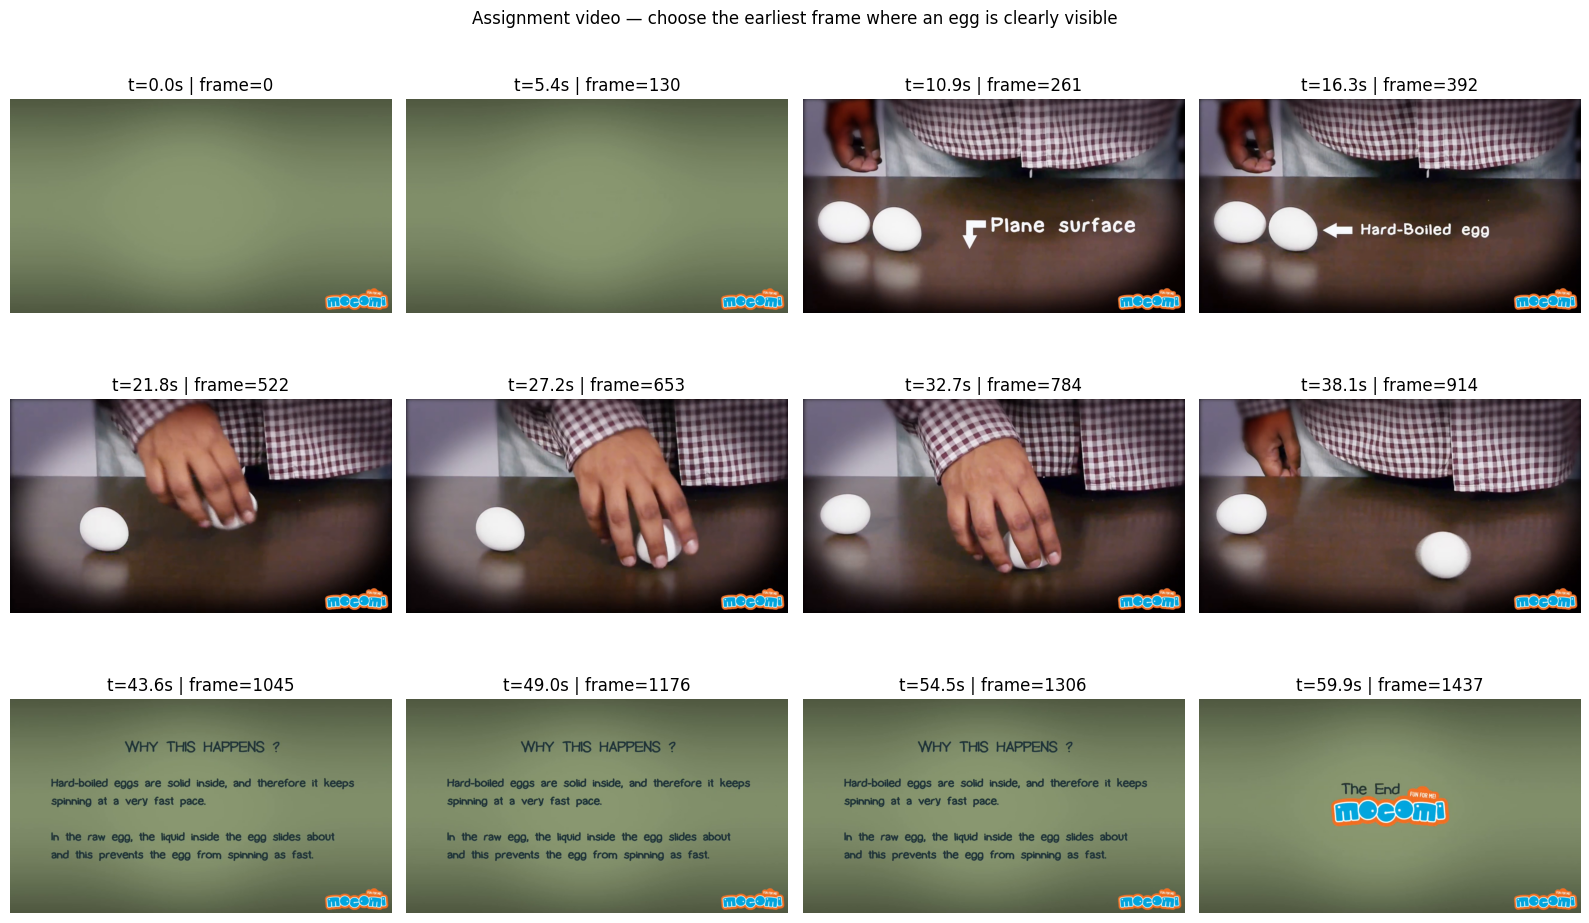

In [7]:
# Install FFmpeg and yt-dlp for downloading/converting the assignment video.
!apt-get -qq update && apt-get -qq install -y ffmpeg
!pip -q install -U yt-dlp

import os, sys, glob, shutil, subprocess
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

VIDEO_URL = "https://www.youtube.com/watch?v=Y4JyV94y2_A"
VIDEO_DIR = PROJECT_DIR / "video_tracking"
VIDEO_DIR.mkdir(parents=True, exist_ok=True)
VIDEO_PATH = Path("/content/egg_spinning_assignment.mp4")

# Download at up to 720p and remux/re-encode to MP4 for reliable OpenCV/FFmpeg reading.
cmd = [
    sys.executable, "-m", "yt_dlp",
    "--no-playlist",
    "-f", "bv*[height<=720]+ba/b[height<=720]/b",
    "--recode-video", "mp4",
    "-o", "/content/egg_spinning_assignment.%(ext)s",
    VIDEO_URL,
]

try:
    result = subprocess.run(cmd, text=True, capture_output=True, check=False)
    candidates = sorted(Path("/content").glob("egg_spinning_assignment*.mp4"))
    if candidates:
        shutil.copy2(candidates[-1], VIDEO_PATH)
    else:
        print("Automatic YouTube download did not produce an MP4.")
        print((result.stderr or result.stdout)[-2500:])
except Exception as exc:
    print("yt-dlp download failed:", repr(exc))

# Fallback: upload a locally downloaded MP4 if YouTube blocks the Colab download.
if not VIDEO_PATH.exists():
    from google.colab import files
    print("Upload the assignment video as an MP4 file.")
    uploaded = files.upload()
    mp4s = [name for name in uploaded if name.lower().endswith(".mp4")]
    if not mp4s:
        raise FileNotFoundError("Please upload the assignment video in MP4 format.")
    shutil.copy2(mp4s[0], VIDEO_PATH)

print("Video file:", VIDEO_PATH)
print("Size (MB):", round(VIDEO_PATH.stat().st_size / (1024 * 1024), 2))

# Read video properties and create a contact sheet to choose a seed frame.
cap_preview = cv2.VideoCapture(str(VIDEO_PATH))
if not cap_preview.isOpened():
    raise RuntimeError("OpenCV could not open the video. Check the MP4 file.")
VIDEO_FPS = cap_preview.get(cv2.CAP_PROP_FPS) or 25.0
VIDEO_FRAME_COUNT = int(cap_preview.get(cv2.CAP_PROP_FRAME_COUNT))
VIDEO_WIDTH = int(cap_preview.get(cv2.CAP_PROP_FRAME_WIDTH))
VIDEO_HEIGHT = int(cap_preview.get(cv2.CAP_PROP_FRAME_HEIGHT))
VIDEO_DURATION = VIDEO_FRAME_COUNT / VIDEO_FPS
cap_preview.release()

print(f"Resolution: {VIDEO_WIDTH}x{VIDEO_HEIGHT}")
print(f"FPS: {VIDEO_FPS:.2f} | Frames: {VIDEO_FRAME_COUNT} | Duration: {VIDEO_DURATION:.1f}s")

sample_count = min(12, max(4, VIDEO_FRAME_COUNT))
sample_times = np.linspace(0, max(0, VIDEO_DURATION - 0.1), sample_count)
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.ravel()
cap_preview = cv2.VideoCapture(str(VIDEO_PATH))
for ax, sec in zip(axes, sample_times):
    cap_preview.set(cv2.CAP_PROP_POS_MSEC, float(sec) * 1000)
    ok, frame = cap_preview.read()
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"t={sec:.1f}s | frame={int(sec * VIDEO_FPS)}")
    else:
        ax.set_title(f"t={sec:.1f}s | unavailable")
    ax.axis("off")
cap_preview.release()
for ax in axes[len(sample_times):]:
    ax.axis("off")
plt.suptitle("Assignment video — choose the earliest frame where an egg is clearly visible")
plt.tight_layout()
plt.show()


Available system RAM before preprocessing: 4.32 GB
SAM input: /content/egg_spinning_assignment_sam_lowram.mp4
Resolution: 640x360
FPS: 2.00 | Frames: 120 | Duration: 60.0s
Approx. OpenCV frame-loader RAM peak: 1.70 GB (estimate, excludes model/runtime overhead)
Available system RAM after preprocessing: 4.70 GB


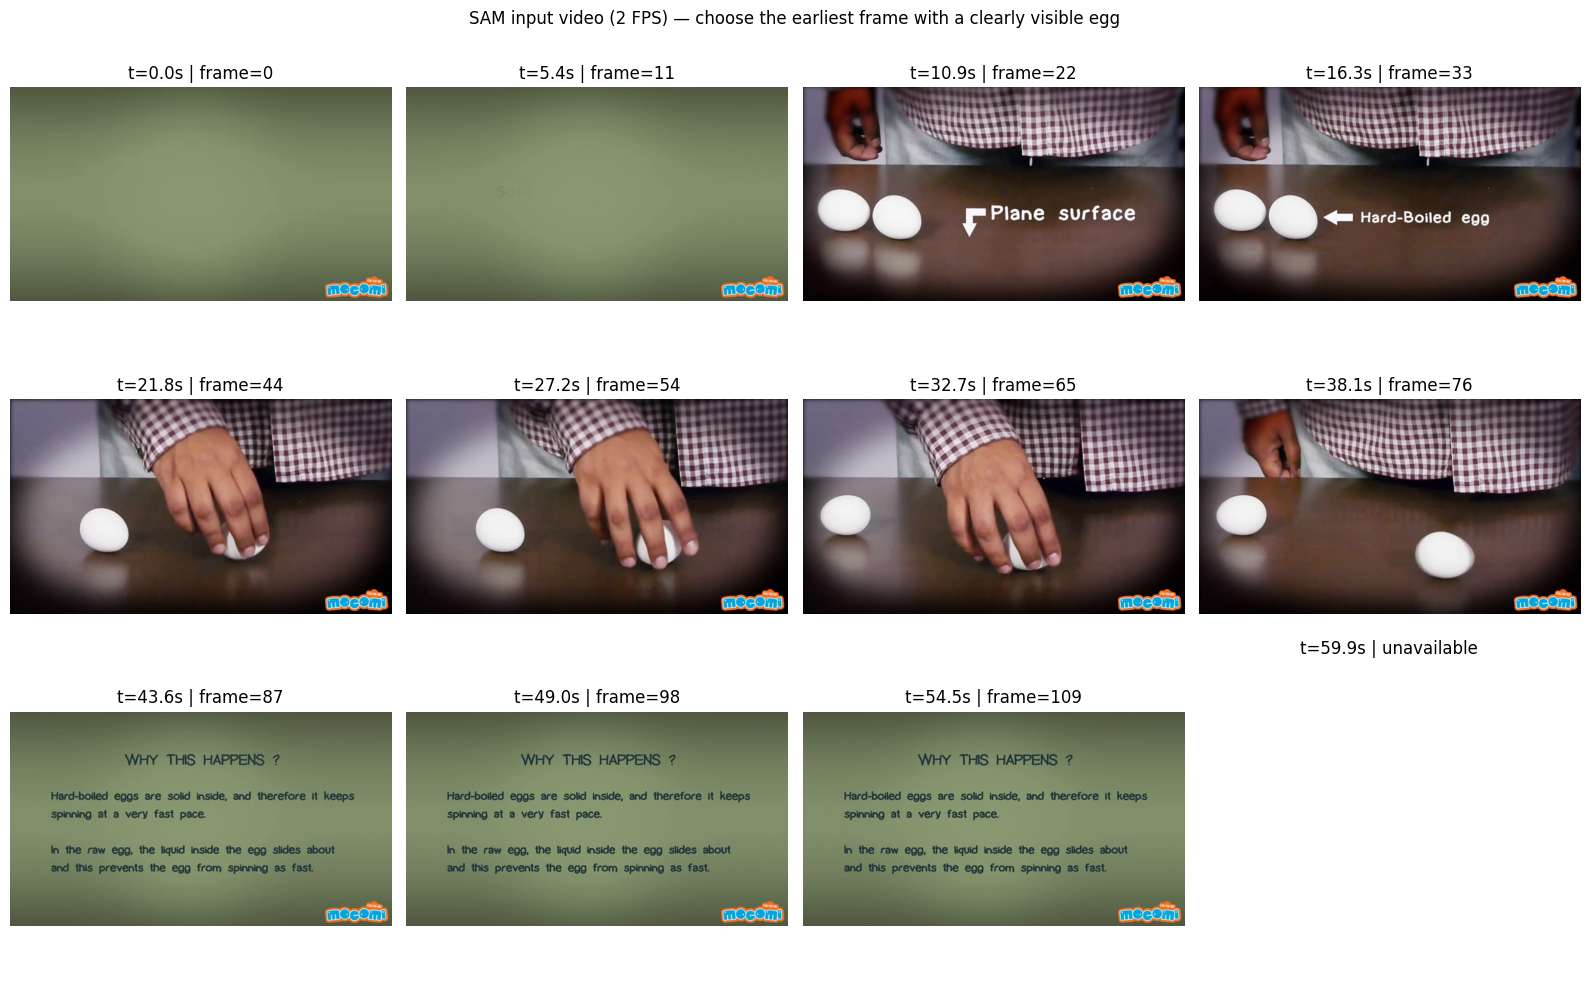

Use the timestamp above in the next PROMPT_TIME_SEC cell.


In [8]:
# LOW-RAM preprocessing for Colab.
# Run this AFTER the original video download cell and BEFORE selecting PROMPT_TIME_SEC.
# Important: always start from the ORIGINAL downloaded video, never re-encode the
# already-downsampled inference file on repeated runs.

import subprocess
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import psutil

ORIGINAL_VIDEO_PATH = Path("/content/egg_spinning_assignment.mp4")
if not ORIGINAL_VIDEO_PATH.exists():
    raise FileNotFoundError(
        f"Original video not found: {ORIGINAL_VIDEO_PATH}. Re-run the YouTube download cell first."
    )

# Start conservatively. For more temporal detail, test 3 or 4 FPS after a successful run.
INFERENCE_FPS = 2
MAX_VIDEO_WIDTH = 640
SAM_VIDEO_PATH = Path("/content/egg_spinning_assignment_sam_lowram.mp4")

ram_before_gb = psutil.virtual_memory().available / (1024 ** 3)
print(f"Available system RAM before preprocessing: {ram_before_gb:.2f} GB")

cmd = [
    "ffmpeg", "-hide_banner", "-loglevel", "error", "-y",
    "-i", str(ORIGINAL_VIDEO_PATH),
    "-vf", f"fps={INFERENCE_FPS},scale=w='min({MAX_VIDEO_WIDTH},iw)':h=-2",
    "-an",
    "-c:v", "libx264", "-preset", "ultrafast", "-crf", "25",
    "-pix_fmt", "yuv420p",
    str(SAM_VIDEO_PATH),
]
subprocess.run(cmd, check=True)

# All downstream cells must use this smaller file.
VIDEO_PATH = SAM_VIDEO_PATH

cap = cv2.VideoCapture(str(VIDEO_PATH))
if not cap.isOpened():
    raise RuntimeError(f"Could not open preprocessed video: {VIDEO_PATH}")
VIDEO_FPS = cap.get(cv2.CAP_PROP_FPS) or float(INFERENCE_FPS)
VIDEO_FRAME_COUNT = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
VIDEO_WIDTH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
VIDEO_HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
VIDEO_DURATION = VIDEO_FRAME_COUNT / VIDEO_FPS

# Approximate peak temporary RAM in the upstream OpenCV loader:
# one uint8 frame in its Python list + one float32 stacked frame.
# SAM resizes every input frame to 1008x1008 internally, irrespective of this source width.
bytes_per_frame_est = 1008 * 1008 * 3 * (1 + 4)
loader_peak_est_gb = VIDEO_FRAME_COUNT * bytes_per_frame_est / (1024 ** 3)

print(f"SAM input: {VIDEO_PATH}")
print(f"Resolution: {VIDEO_WIDTH}x{VIDEO_HEIGHT}")
print(f"FPS: {VIDEO_FPS:.2f} | Frames: {VIDEO_FRAME_COUNT} | Duration: {VIDEO_DURATION:.1f}s")
print(f"Approx. OpenCV frame-loader RAM peak: {loader_peak_est_gb:.2f} GB (estimate, excludes model/runtime overhead)")
print(f"Available system RAM after preprocessing: {psutil.virtual_memory().available / (1024 ** 3):.2f} GB")

if loader_peak_est_gb > 4.0:
    print("WARNING: Estimated loader peak is high. Lower INFERENCE_FPS to 1 before opening a SAM session.")

# Rebuild the contact sheet from the exact file SAM will process.
sample_count = min(12, max(4, VIDEO_FRAME_COUNT))
sample_times = np.linspace(0, max(0, VIDEO_DURATION - 0.1), sample_count)
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.ravel()
for ax, sec in zip(axes, sample_times):
    cap.set(cv2.CAP_PROP_POS_MSEC, float(sec) * 1000)
    ok, frame = cap.read()
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"t={sec:.1f}s | frame={int(round(sec * VIDEO_FPS))}")
    else:
        ax.set_title(f"t={sec:.1f}s | unavailable")
    ax.axis("off")
cap.release()
for ax in axes[len(sample_times):]:
    ax.axis("off")
plt.suptitle(f"SAM input video ({INFERENCE_FPS} FPS) — choose the earliest frame with a clearly visible egg")
plt.tight_layout()
plt.show()

print("Use the timestamp above in the next PROMPT_TIME_SEC cell.")

In [10]:
# ============================================================
# SAM 3.1 IMAGE SEGMENTATION + STABLE TWO-EGG ID TRACKING
# Frame-wise segmentation avoids the high-memory native video
# propagation path. Track IDs are persistent: no new IDs are
# created when an egg changes position or is briefly undetected.
# ============================================================

import gc, json, math
import cv2
import torch
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm
from collections import deque, defaultdict
from scipy.optimize import linear_sum_assignment
from IPython.display import Video, display

# ---------------------------- Configuration ----------------------------
TRACKED_VIDEO_PATH = VIDEO_DIR / 'egg_tracking_sam3_1_stable_ids.mp4'
TRACK_CSV_PATH = VIDEO_DIR / 'egg_tracking_sam3_1_tracks.csv'
TRACK_SUMMARY_PATH = VIDEO_DIR / 'egg_tracking_sam3_1_summary.json'

EXPECTED_EGGS = 2
SCORE_THRESHOLD = 0.45            # Lower slightly to reduce temporary detection loss.
MIN_MASK_AREA_FRACTION = 0.0005
MAX_MASK_AREA_FRACTION = 0.45
MAX_DETECTION_CANDIDATES = 8
HISTORY_LENGTH = 8                # Past matched positions used for motion prediction.
MAX_PREDICTION_HORIZON = 12       # Frames; extrapolation is capped after long gaps.
MAX_MATCH_COST = 0.99             # IDs are retained; no new ID is spawned on mismatch.

COLORS = {
    1: (0, 220, 255),
    2: (255, 120, 30),
}

# T4 has no native BF16 support; use FP16 there. Newer GPUs can use BF16.
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print('GPU:', torch.cuda.get_device_name(0))
print('Autocast dtype:', AMP_DTYPE)
print('Available GPU memory:', round(torch.cuda.mem_get_info()[0] / 1024**3, 2), 'GB')

# ---------------------------- Detection helpers ----------------------------
def binary_mask_iou(a, b):
    inter = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return float(inter / union) if union else 0.0


def bbox_iou(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0, ix2 - ix1), max(0, iy2 - iy1)
    inter = iw * ih
    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)
    union = area_a + area_b - inter
    return float(inter / union) if union > 0 else 0.0


def appearance_histogram(frame_bgr, mask):
    # A low-weight appearance cue helps distinguish two similar-sized eggs.
    hsv = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2HSV)
    mask_u8 = (mask.astype(np.uint8) * 255)
    hist = cv2.calcHist([hsv], [0, 1], mask_u8, [12, 8], [0, 180, 0, 256])
    cv2.normalize(hist, hist, alpha=1.0, norm_type=cv2.NORM_L1)
    return hist.astype(np.float32)


def detection_from_mask(mask, score, frame_bgr):
    mask = np.asarray(mask).astype(bool)
    h, w = frame_bgr.shape[:2]
    if mask.shape != (h, w):
        mask = cv2.resize(mask.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)
    ys, xs = np.where(mask)
    if len(xs) == 0:
        return None
    x1, x2 = int(xs.min()), int(xs.max()) + 1
    y1, y2 = int(ys.min()), int(ys.max()) + 1
    area = int(mask.sum())
    area_fraction = area / float(h * w)
    if area_fraction < MIN_MASK_AREA_FRACTION or area_fraction > MAX_MASK_AREA_FRACTION:
        return None
    return {
        'mask': mask,
        'score': float(score),
        'centroid': np.array([xs.mean(), ys.mean()], dtype=np.float32),
        'bbox': (x1, y1, x2, y2),
        'area': area,
        'hist': appearance_histogram(frame_bgr, mask),
    }


def remove_duplicate_detections(detections, max_keep=MAX_DETECTION_CANDIDATES):
    # Suppress duplicate SAM masks for the same egg before association.
    ranked = sorted(detections, key=lambda d: d['score'], reverse=True)
    kept = []
    for det in ranked:
        duplicate = False
        for prev in kept:
            if binary_mask_iou(det['mask'], prev['mask']) >= 0.78 or bbox_iou(det['bbox'], prev['bbox']) >= 0.82:
                duplicate = True
                break
        if not duplicate:
            kept.append(det)
        if len(kept) >= max_keep:
            break
    return kept


def collect_detections(masks, scores, frame_bgr):
    found = []
    if masks is None:
        return found
    for mask, score in zip(masks, scores):
        score = float(score)
        if score < SCORE_THRESHOLD:
            continue
        det = detection_from_mask(mask, score, frame_bgr)
        if det is not None:
            found.append(det)
    return remove_duplicate_detections(found)

# ---------------------------- Persistent track model ----------------------------
def predict_track_center(track, frame_idx, image_diagonal):
    observations = list(track['history'])[-HISTORY_LENGTH:]
    last_frame, last_center = observations[-1]
    gap = max(0, frame_idx - last_frame)
    if len(observations) < 2 or gap == 0:
        return last_center.copy()

    # Least-squares constant-velocity estimate from recent observations.
    times = np.array([item[0] for item in observations], dtype=np.float32)
    centers = np.stack([item[1] for item in observations]).astype(np.float32)
    times = times - times[-1]
    vx = float(np.polyfit(times, centers[:, 0], 1)[0])
    vy = float(np.polyfit(times, centers[:, 1], 1)[0])
    velocity = np.array([vx, vy], dtype=np.float32)
    speed = float(np.linalg.norm(velocity))
    max_speed = 0.35 * image_diagonal
    if speed > max_speed:
        velocity *= max_speed / max(speed, 1e-6)
    horizon = min(gap, MAX_PREDICTION_HORIZON)
    return last_center + velocity * horizon


def predicted_bbox(track, predicted_center):
    x1, y1, x2, y2 = track['bbox']
    width, height = x2 - x1, y2 - y1
    cx, cy = predicted_center
    return (int(round(cx - width / 2)), int(round(cy - height / 2)),
            int(round(cx + width / 2)), int(round(cy + height / 2)))


def appearance_distance(hist_a, hist_b):
    return float(cv2.compareHist(hist_a, hist_b, cv2.HISTCMP_BHATTACHARYYA))


def association_cost(track, detection, frame_idx, image_diagonal):
    predicted = predict_track_center(track, frame_idx, image_diagonal)
    distance = float(np.linalg.norm(predicted - detection['centroid']))

    x1, y1, x2, y2 = track['bbox']
    last_diag = math.sqrt(max(1, (x2 - x1) * (y2 - y1)))
    cx1, cy1, cx2, cy2 = detection['bbox']
    current_diag = math.sqrt(max(1, (cx2 - cx1) * (cy2 - cy1)))
    object_scale = max((last_diag + current_diag) / 2.0, 24.0)
    gap = max(1, frame_idx - track['last_frame'])
    # Distance gate grows with time since last observation, allowing fast motion.
    distance_gate = max(3.2 * object_scale, 0.10 * image_diagonal) * min(1.0 + 0.20 * (gap - 1), 3.0)
    motion_cost = min(distance / max(distance_gate, 1.0), 1.5) / 1.5

    pred_box = predicted_bbox(track, predicted)
    box_cost = 1.0 - bbox_iou(pred_box, detection['bbox'])
    area_cost = min(abs(math.log((detection['area'] + 1) / (track['area'] + 1))), 1.5) / 1.5
    appearance_cost = min(appearance_distance(track['hist'], detection['hist']), 1.0)

    # Motion is the primary identity cue; colour/shape are supporting cues.
    return 0.58 * motion_cost + 0.18 * box_cost + 0.10 * area_cost + 0.14 * appearance_cost


def initialize_two_tracks(detections, frame_idx):
    # Select the two largest plausible egg detections and assign stable initial IDs
    # left-to-right. This naming convention is also stated in the report.
    if len(detections) < EXPECTED_EGGS:
        return None
    selected = sorted(detections, key=lambda d: d['area'], reverse=True)[:EXPECTED_EGGS]
    selected = sorted(selected, key=lambda d: (float(d['centroid'][0]), float(d['centroid'][1])))
    tracks = {}
    for object_id, det in enumerate(selected, start=1):
        tracks[object_id] = {
            'history': deque([(frame_idx, det['centroid'].copy())], maxlen=HISTORY_LENGTH),
            'last_frame': frame_idx,
            'bbox': det['bbox'],
            'area': det['area'],
            'hist': det['hist'].copy(),
            'last_mask': det['mask'].copy(),
            'missed': 0,
        }
    return tracks, {0: 1, 1: 2}, selected


def associate_persistent_ids(detections, tracks, frame_idx, image_diagonal):
    """Associate current detections to existing IDs; never generate a new ID."""
    if not detections or not tracks:
        for track in tracks.values():
            track['missed'] += 1
        return {}, {}

    object_ids = sorted(tracks.keys())
    cost = np.full((len(object_ids), len(detections)), 10.0, dtype=np.float32)
    for i, object_id in enumerate(object_ids):
        for j, det in enumerate(detections):
            cost[i, j] = association_cost(tracks[object_id], det, frame_idx, image_diagonal)

    rows, cols = linear_sum_assignment(cost)
    assignments = {}
    used_detections = set()
    matched_costs = {}
    for r, c in zip(rows, cols):
        object_id = object_ids[r]
        if float(cost[r, c]) <= MAX_MATCH_COST:
            assignments[c] = object_id
            used_detections.add(c)
            matched_costs[object_id] = float(cost[r, c])

    matched_ids = set(assignments.values())
    for object_id, track in tracks.items():
        if object_id not in matched_ids:
            track['missed'] += 1

    for det_idx, object_id in assignments.items():
        det = detections[det_idx]
        track = tracks[object_id]
        # Exponential smoothing keeps appearance stable despite lighting/rotation.
        track['hist'] = 0.85 * track['hist'] + 0.15 * det['hist']
        cv2.normalize(track['hist'], track['hist'], alpha=1.0, norm_type=cv2.NORM_L1)
        track['history'].append((frame_idx, det['centroid'].copy()))
        track['last_frame'] = frame_idx
        track['bbox'] = det['bbox']
        track['area'] = det['area']
        track['last_mask'] = det['mask'].copy()
        track['missed'] = 0

    return assignments, matched_costs

# ---------------------------- Video reader/writer ----------------------------
cap = cv2.VideoCapture(str(VIDEO_PATH))
if not cap.isOpened():
    raise RuntimeError(f'Cannot open input video: {VIDEO_PATH}')
SOURCE_FPS = cap.get(cv2.CAP_PROP_FPS) or VIDEO_FPS
FRAME_COUNT = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
WIDTH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
IMAGE_DIAGONAL = float(np.hypot(WIDTH, HEIGHT))

writer = cv2.VideoWriter(
    str(TRACKED_VIDEO_PATH), cv2.VideoWriter_fourcc(*'mp4v'),
    SOURCE_FPS, (WIDTH, HEIGHT)
)
if not writer.isOpened():
    cap.release()
    raise RuntimeError('Could not create annotated output video.')

tracks = None
track_rows = []
processed_frames = 0
initialized_frame = None
id_history = defaultdict(list)

try:
    for frame_idx in tqdm(range(FRAME_COUNT), desc='SAM 3.1 two-egg tracking'):
        ok, frame = cap.read()
        if not ok:
            break

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        pil_image = Image.fromarray(rgb)
        with torch.inference_mode():
            with torch.amp.autocast('cuda', dtype=AMP_DTYPE):
                masks, boxes, scores = segment_image(pil_image)

        detections = collect_detections(masks, scores, frame)
        annotated = frame.copy()
        assignments = {}
        matched_costs = {}

        if tracks is None:
            seeded = initialize_two_tracks(detections, frame_idx)
            if seeded is not None:
                tracks, assignments, detections = seeded
                initialized_frame = frame_idx
                for det_idx, object_id in assignments.items():
                    det = detections[det_idx]
                    id_history[object_id].append(tuple(det['centroid'].astype(int)))
                    track_rows.append({
                        'frame_index': frame_idx, 'timestamp_sec': round(frame_idx / SOURCE_FPS, 3),
                        'object_id': object_id, 'confidence': det['score'],
                        'centroid_x': int(det['centroid'][0]), 'centroid_y': int(det['centroid'][1]),
                        'bbox_x': det['bbox'][0], 'bbox_y': det['bbox'][1],
                        'bbox_width': det['bbox'][2] - det['bbox'][0],
                        'bbox_height': det['bbox'][3] - det['bbox'][1],
                        'mask_area_pixels': det['area'], 'association_cost': 0.0,
                    })
            else:
                cv2.putText(annotated, 'Waiting to detect both eggs for stable ID initialization',
                            (15, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)
        else:
            assignments, matched_costs = associate_persistent_ids(detections, tracks, frame_idx, IMAGE_DIAGONAL)

            for det_idx, object_id in assignments.items():
                det = detections[det_idx]
                id_history[object_id].append(tuple(det['centroid'].astype(int)))
                track_rows.append({
                    'frame_index': frame_idx, 'timestamp_sec': round(frame_idx / SOURCE_FPS, 3),
                    'object_id': object_id, 'confidence': det['score'],
                    'centroid_x': int(det['centroid'][0]), 'centroid_y': int(det['centroid'][1]),
                    'bbox_x': det['bbox'][0], 'bbox_y': det['bbox'][1],
                    'bbox_width': det['bbox'][2] - det['bbox'][0],
                    'bbox_height': det['bbox'][3] - det['bbox'][1],
                    'mask_area_pixels': det['area'],
                    'association_cost': matched_costs.get(object_id),
                })

        # Draw matched masks/boxes/labels; missed objects keep their IDs and are
        # shown as temporarily not detected rather than receiving replacement IDs.
        if tracks is not None:
            assigned_ids = set(assignments.values())
            for det_idx, object_id in assignments.items():
                det = detections[det_idx]
                color = COLORS[object_id]
                mask = det['mask']
                overlay = annotated.copy()
                overlay[mask] = color
                annotated = cv2.addWeighted(overlay, 0.38, annotated, 0.62, 0)
                contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                cv2.drawContours(annotated, contours, -1, color, 2)
                x1, y1, x2, y2 = det['bbox']
                cx, cy = det['centroid'].astype(int)
                cv2.rectangle(annotated, (x1, y1), (x2, y2), color, 2)
                cv2.circle(annotated, (cx, cy), 5, color, -1)
                cv2.putText(annotated, f'Egg ID {object_id}', (x1, max(25, y1 - 10)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
                points = id_history[object_id][-30:]
                for p1, p2 in zip(points[:-1], points[1:]):
                    cv2.line(annotated, p1, p2, color, 2)

            for object_id, track in tracks.items():
                if object_id not in assigned_ids and track['missed'] <= 10:
                    pred = predict_track_center(track, frame_idx, IMAGE_DIAGONAL).astype(int)
                    px, py = int(pred[0]), int(pred[1])
                    if 0 <= px < WIDTH and 0 <= py < HEIGHT:
                        cv2.circle(annotated, (px, py), 12, COLORS[object_id], 2)
                        cv2.putText(annotated, f'ID {object_id} temporarily missing',
                                    (max(5, px - 75), max(20, py - 18)),
                                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, COLORS[object_id], 2)

        n_tracked = len(assignments)
        cv2.putText(annotated, f'SAM 3.1 | Frame {frame_idx} | matched eggs: {n_tracked}/{EXPECTED_EGGS}',
                    (15, HEIGHT - 15), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)
        writer.write(annotated)
        processed_frames += 1

        del pil_image, rgb, masks, boxes, scores, detections, annotated
        if processed_frames % 10 == 0:
            gc.collect()
            torch.cuda.empty_cache()
finally:
    cap.release()
    writer.release()
    gc.collect()
    torch.cuda.empty_cache()

tracks_df = pd.DataFrame(track_rows)
tracks_df.to_csv(TRACK_CSV_PATH, index=False)

summary = {
    'input_video': str(VIDEO_PATH),
    'output_video': str(TRACKED_VIDEO_PATH),
    'processed_frames': int(processed_frames),
    'video_fps': float(SOURCE_FPS),
    'expected_egg_count': EXPECTED_EGGS,
    'initialization_frame': initialized_frame,
    'initial_id_assignment': 'Left-to-right order in the first frame where both eggs are detected.',
    'id_policy': 'Exactly two persistent IDs are initialised; no new IDs are minted after missed detections.',
    'unique_ids': sorted(tracks_df['object_id'].unique().astype(int).tolist()) if not tracks_df.empty else [],
    'per_id_detected_frames': tracks_df.groupby('object_id')['frame_index'].nunique().astype(int).to_dict() if not tracks_df.empty else {},
    'tracking_records': int(len(tracks_df)),
    'notes': 'IDs can be temporarily unobserved when SAM misses an egg. Appearance and motion association reduce ID switches but cannot guarantee identity through complete occlusion or visually indistinguishable crossings.'
}
with open(TRACK_SUMMARY_PATH, 'w') as f:
    json.dump(summary, f, indent=2)

print('========== TRACKING COMPLETE ==========')
print('Frames processed:', processed_frames)
print('First frame where both eggs were detected:', initialized_frame)
print('Persistent IDs:', summary['unique_ids'])
print('Detected frames per ID:', summary['per_id_detected_frames'])
print('Annotated video:', TRACKED_VIDEO_PATH)
print('Track CSV:', TRACK_CSV_PATH)
print('Summary:', TRACK_SUMMARY_PATH)
display(tracks_df.groupby('object_id')['frame_index'].nunique().rename('detected_frames').to_frame())
display(Video(str(TRACKED_VIDEO_PATH), embed=True, width=800))


GPU: Tesla T4
Autocast dtype: torch.bfloat16
Available GPU memory: 10.98 GB


SAM 3.1 two-egg tracking:   0%|          | 0/120 [00:00<?, ?it/s]

========== TRACKING COMPLETE ==========
Frames processed: 120
First frame where both eggs were detected: 18
Persistent IDs: [1, 2]
Detected frames per ID: {1: 66, 2: 65}
Annotated video: /content/drive/MyDrive/egg_cv_assignment/video_tracking/egg_tracking_sam3_1_stable_ids.mp4
Track CSV: /content/drive/MyDrive/egg_cv_assignment/video_tracking/egg_tracking_sam3_1_tracks.csv
Summary: /content/drive/MyDrive/egg_cv_assignment/video_tracking/egg_tracking_sam3_1_summary.json


,detected_frames
object_id,
1,66
2,65
